In [1]:
# This cell is mandatory in all Dymos documentation notebooks.
missing_packages = []
try:
    import openmdao.api as om  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install openmdao[notebooks]
    else:
        missing_packages.append('openmdao')
try:
    import dymos as dm  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !python -m pip install dymos
    else:
        missing_packages.append('dymos')
try:
    import pyoptsparse  # noqa: F401
except ImportError:
    if 'google.colab' in str(get_ipython()):
        !pip install -q condacolab
        import condacolab
        condacolab.install_miniconda()
        !conda install -c conda-forge pyoptsparse
    else:
        missing_packages.append('pyoptsparse')
if missing_packages:
    raise EnvironmentError('This notebook requires the following packages '
                           'please install them and restart this notebook\'s runtime: {",".join(missing_packages)}')

(examples:minimum_time_climb)=
# Supersonic Interceptor Minimum Time Climb

This example is based on the _A/C Min Time to Climb_ example given in
chapter 4 of Bryson {cite}`bryson1999dynamic`. It finds the
angle-of-attack history required to accelerate a supersonic interceptor
from near ground level, Mach 0.4 to an altitude of 20 km and Mach 1.0.

![The free-body-diagram of the min-time-climb problem.](min_time_climb_fbd.png)

The vehicle dynamics are given by

\begin{align}
  \frac{dv}{dt} &= \frac{T}{m} \cos \alpha - \frac{D}{m} - g \sin \gamma \\
  \frac{d\gamma}{dt} &= \frac{T}{m v} \sin \alpha + \frac{L}{m v} - \frac{g \cos \gamma}{v} \\
  \frac{dh}{dt} &= v \sin \gamma \\
  \frac{dr}{dt} &= v \cos \gamma \\
  \frac{dm}{dt} &= - \frac{T}{g I_{sp}}
\end{align}

The initial conditions are

\begin{align}
  r_0 &= 0 \rm{\,m} \\
  h_0 &= 100 \rm{\,m} \\
  v_0 &= 135.964 \rm{\,m/s} \\
  \gamma_0 &= 0 \rm{\,deg} \\
  m_0 &= 19030.468 \rm{\,kg}
\end{align}

and the final conditions are

\begin{align}
  h_f &= 20000 \rm{\,m} \\
  M_f &= 1.0 \\
  \gamma_0 &= 0 \rm{\,deg}
\end{align}

## The ODE System: min_time_climb_ode.py

The top level ODE definition is a _Group_ that connects several subsystems.

In [2]:
om.display_source("dymos.examples.min_time_climb.test.aero_partial_coloring")

import openmdao.api as om
from .dynamic_pressure_comp_partial_coloring import DynamicPressureCompFD
from ..aero.dynamic_pressure_comp import DynamicPressureComp
from ..aero.lift_drag_force_comp import LiftDragForceComp
from ..aero.cd0_comp import CD0Comp
from ..aero.kappa_comp import KappaComp
from ..aero.cla_comp import CLaComp
from ..aero.cl_comp import CLComp
from ..aero.cd_comp import CDComp
from ..aero.mach_comp import MachComp


class AeroGroup(om.Group):
    """
    The purpose of the AeroGroup is to compute the aerodynamic forces on the
    
    aircraft in the body frame.

    Parameters
    ----------
    v : float
        air-relative velocity (m/s)
    sos : float
        local speed of sound (m/s)
    rho : float
        atmospheric density (kg/m**3)
    alpha : float
        angle of attack (rad)
    S : float
        aerodynamic reference area (m**2)

    """

    def initialize(self):
        self.options.declare('num_nodes', types=int,
                             desc='Number of nodes to be evaluated in the RHS')
        self.options.declare('fd', types=bool, default=False, desc='If True, use fd for partials for dynamic pressure')
        self.options.declare('partial_coloring', types=bool, default=False,
                             desc='If True and fd is True, color the approximated partials of dynamic pressure')

    def setup(self):
        nn = self.options['num_nodes']

        if self.options['fd']:
            q_comp = DynamicPressureCompFD(num_nodes=nn, partial_coloring=self.options['partial_coloring'])
        else:
            q_comp = DynamicPressureComp(num_nodes=nn)

        self.add_subsystem(name='mach_comp',
                           subsys=MachComp(num_nodes=nn),
                           promotes_inputs=['v', 'sos'],
                           promotes_outputs=['mach'])

        self.add_subsystem(name='cd0_comp',
                           subsys=CD0Comp(num_nodes=nn),
                           promotes_inputs=['mach'],
                           promotes_outputs=['CD0'])

        self.add_subsystem(name='kappa_comp',
                           subsys=KappaComp(num_nodes=nn),
                           promotes_inputs=['mach'],
                           promotes_outputs=['kappa'])

        self.add_subsystem(name='cla_comp',
                           subsys=CLaComp(num_nodes=nn),
                           promotes_inputs=['mach'],
                           promotes_outputs=['CLa'])

        self.add_subsystem(name='CL_comp',
                           subsys=CLComp(num_nodes=nn),
                           promotes_inputs=['alpha', 'CLa'],
                           promotes_outputs=['CL'])

        self.add_subsystem(name='CD_comp',
                           subsys=CDComp(num_nodes=nn),
                           promotes_inputs=['CD0', 'alpha', 'CLa', 'kappa'],
                           promotes_outputs=['CD'])

        self.add_subsystem(name='q_comp',
                           subsys=q_comp,
                           promotes_inputs=['rho', 'v'],
                           promotes_outputs=['q'])

        self.add_subsystem(name='lift_drag_force_comp',
                           subsys=LiftDragForceComp(num_nodes=nn),
                           promotes_inputs=['CL', 'CD', 'q', 'S'],
                           promotes_outputs=['f_lift', 'f_drag'])

In [3]:
import openmdao.api as om
from dymos.models.eom import FlightPathEOM2D
from dymos.examples.min_time_climb.prop import PropGroup
from dymos.models.atmosphere import USatm1976Comp
from dymos.examples.min_time_climb.test.aero_partial_coloring import AeroGroup


class MinTimeClimbODE(om.Group):

    def initialize(self):
        self.options.declare('num_nodes', types=int)
        self.options.declare('fd', types=bool, default=False, desc='If True, use fd for partials')
        self.options.declare('partial_coloring', types=bool, default=False,
                             desc='If True and fd is True, color the approximated partials')

    def setup(self):
        nn = self.options['num_nodes']

        self.add_subsystem(name='atmos',
                           subsys=USatm1976Comp(num_nodes=nn, h_def='geodetic'),
                           promotes_inputs=['h'])

        self.add_subsystem(name='aero',
                           subsys=AeroGroup(num_nodes=nn,
                                            fd=self.options['fd'],
                                            partial_coloring=self.options['partial_coloring']),
                           promotes_inputs=['v', 'alpha', 'S'])

        self.connect('atmos.sos', 'aero.sos')
        self.connect('atmos.rho', 'aero.rho')

        self.add_subsystem(name='prop',
                           subsys=PropGroup(num_nodes=nn),
                           promotes_inputs=['h', 'Isp', 'throttle'])

        self.connect('aero.mach', 'prop.mach')

        self.add_subsystem(name='flight_dynamics',
                           subsys=FlightPathEOM2D(num_nodes=nn),
                           promotes_inputs=['m', 'v', 'gam', 'alpha'])

        self.connect('aero.f_drag', 'flight_dynamics.D')
        self.connect('aero.f_lift', 'flight_dynamics.L')
        self.connect('prop.thrust', 'flight_dynamics.T')


## Building and running the problem

In the following code we follow the following process to solve the
problem:

In [4]:
%matplotlib inline

In [5]:
import matplotlib.pyplot as plt

import openmdao.api as om

import dymos as dm
from dymos.examples.plotting import plot_results

#
# Instantiate the problem and configure the optimization driver
#
p = om.Problem(model=om.Group())

p.driver = om.pyOptSparseDriver()
p.driver.options['optimizer'] = 'SLSQP'
p.driver.declare_coloring()

#
# Instantiate the trajectory and phase
#
traj = dm.Trajectory()

phase = dm.Phase(ode_class=MinTimeClimbODE,
                 transcription=dm.GaussLobatto(num_segments=15, compressed=False))

traj.add_phase('phase0', phase)

p.model.add_subsystem('traj', traj)

#
# Set the options on the optimization variables
# Note the use of explicit state units here since much of the ODE uses imperial units
# and we prefer to solve this problem using metric units.
#
phase.set_time_options(fix_initial=True, duration_bounds=(50, 400),
                       duration_ref=100.0)

phase.add_state('r', fix_initial=True, lower=0, upper=1.0E6, units='m',
                ref=1.0E3, defect_ref=1.0E3,
                rate_source='flight_dynamics.r_dot')

phase.add_state('h', fix_initial=True, lower=0, upper=20000.0, units='m',
                ref=1.0E2, defect_ref=1.0E2,
                rate_source='flight_dynamics.h_dot')

phase.add_state('v', fix_initial=True, lower=10.0, units='m/s',
                ref=1.0E2, defect_ref=1.0E2,
                rate_source='flight_dynamics.v_dot')

phase.add_state('gam', fix_initial=True, lower=-1.5, upper=1.5, units='rad',
                ref=1.0, defect_ref=1.0,
                rate_source='flight_dynamics.gam_dot')

phase.add_state('m', fix_initial=True, lower=10.0, upper=1.0E5, units='kg',
                ref=1.0E3, defect_ref=1.0E3,
                rate_source='prop.m_dot')

phase.add_control('alpha', units='deg', lower=-8.0, upper=8.0, scaler=1.0,
                  rate_continuity=True, rate_continuity_scaler=100.0,
                  rate2_continuity=False)

phase.add_parameter('S', val=49.2386, units='m**2', opt=False, targets=['S'])
phase.add_parameter('Isp', val=1600.0, units='s', opt=False, targets=['Isp'])
phase.add_parameter('throttle', val=1.0, opt=False, targets=['throttle'])

#
# Setup the boundary and path constraints
#
phase.add_boundary_constraint('h', loc='final', equals=20000, scaler=1.0E-3)
phase.add_boundary_constraint('aero.mach', loc='final', equals=1.0)
phase.add_boundary_constraint('gam', loc='final', equals=0.0)

phase.add_path_constraint(name='h', lower=100.0, upper=20000, ref=20000)
phase.add_path_constraint(name='aero.mach', lower=0.1, upper=1.8)

# Minimize time at the end of the phase
phase.add_objective('time', loc='final', ref=1.0)

p.model.linear_solver = om.DirectSolver()

#
# Setup the problem and set the initial guess
#
p.setup(check=True)

phase.set_time_val(initial=0.0, duration=350)
phase.set_state_val('r', [0.0, 50000.0])
phase.set_state_val('h', [100.0, 20000.0])
phase.set_state_val('v', [135.964, 283.159])
phase.set_state_val('gam', [0.0, 0.0])
phase.set_state_val('m', [19030.468, 10000.])
phase.set_control_val('alpha', [0.0, 0.0])

#
# Solve for the optimal trajectory
#
dm.run_problem(p, simulate=True)



INFO: checking out_of_order...


INFO:     out_of_order check complete (0.001215 sec).


INFO: checking system...


INFO:     system check complete (0.000054 sec).


INFO: checking solvers...


...

/home/runner/work/dymos/dymos/.openmdao-pixi/.pixi/envs/dev/lib/python3.13/site-packages/openmdao/core/total_jac.py:1925: DerivativesWarning:The following constraints or objectives cannot be impacted by the design variables of the problem at the current design point:
  traj.phase0.h[path], inds=[(0, 0)]
  traj.phase0.mach[path], inds=[(0, 0)]





Optimization Problem -- Optimization using pyOpt_sparse
    Objective Function: _objfunc

    Solution: 
--------------------------------------------------------------------------------
    Total Time:                    4.7430
       User Objective Time :       1.1514
       User Sensitivity Time :     0.9741
       Interface Time :            0.3945
       Opt Solver Time:            2.2230
    Calls to Objective Function :      94
    Calls to Sens Function :           84


   Objectives
      Index  Name                     Value
          0  traj.phase0.t     3.252582E+02

   Variables (c - continuous, i - integer, d - discrete)
      Index  Name                            Type      Lower Bound            Value      Upper Bound     Status
          0  traj.phase0.t_duration_0           c     5.000000E-01     3.252582E+00     4.000000E+00           
          1  traj.phase0.states:r_0             c     0.000000E+00     4.337684E+00     1.000000E+03           
          2  traj.ph


Simulating trajectory traj


Done simulating trajectory traj


Problem: min_time_climb
Driver:  pyOptSparseDriver
  success     : True
  iterations  : 96
  runtime     : 5.2211E+00 s
  model_evals : 96
  model_time  : 1.1246E+00 s
  deriv_evals : 85
  deriv_time  : 9.6823E-01 s
  exit_status : SUCCESS

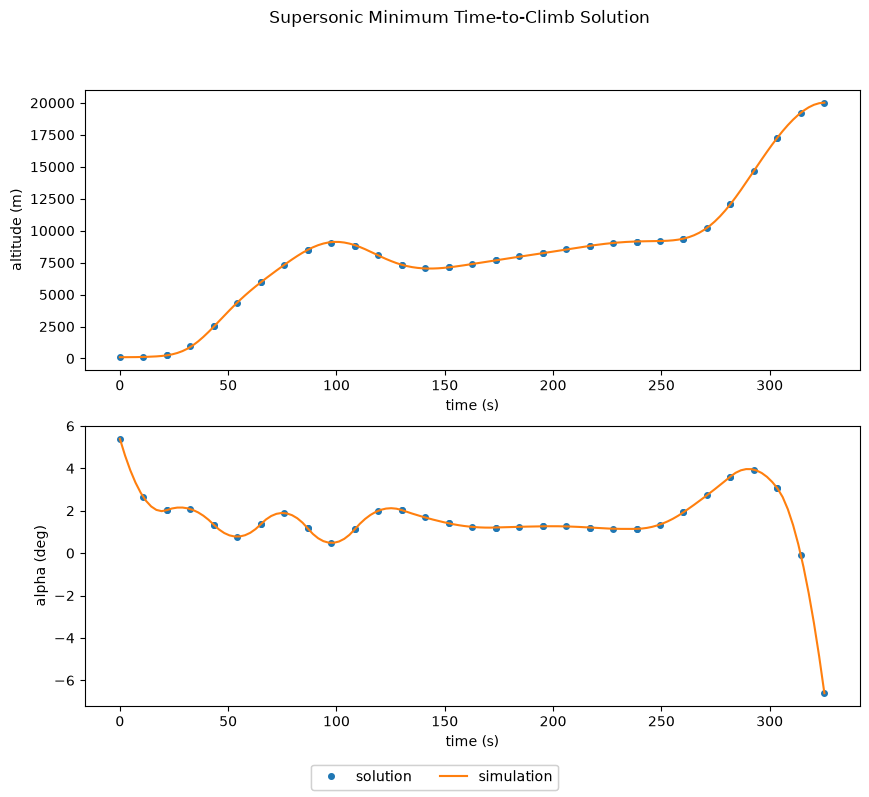

In [6]:
sol = om.CaseReader(p.get_outputs_dir() / 'dymos_solution.db').get_case('final')
sim = om.CaseReader(traj.sim_prob.get_outputs_dir() / 'dymos_simulation.db').get_case('final')

plot_results([('traj.phase0.timeseries.time', 'traj.phase0.timeseries.h',
               'time (s)', 'altitude (m)'),
              ('traj.phase0.timeseries.time', 'traj.phase0.timeseries.alpha',
               'time (s)', 'alpha (deg)')],
             title='Supersonic Minimum Time-to-Climb Solution',
             p_sol=sol, p_sim=sim)

plt.show()

In [7]:
from openmdao.utils.assert_utils import assert_near_equal

assert_near_equal(p.get_val('traj.phase0.t_duration'), 321.0, tolerance=1.0E-1)

np.float64(0.013265575404245184)

## References

```{bibliography}
:filter: docname in docnames
```